# TF-IDF — Modern External Dataset Evaluation

**Purpose:** Evaluate three **already-trained HC3 TF-IDF classifiers** (Logistic Regression, Linear SVM, and FFNN) on the held-out modern dataset. **No model fitting, retraining, vectorizer refitting, or threshold tuning** happens here.

Labels: `0 = human`, `1 = AI`. Results are saved for a later cross-family comparison notebook.

## 1. Imports and project paths

In [15]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# Works when Jupyter starts in the repo root OR notebooks/evaluation.
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents]
                     if (p / 'models').is_dir() and (p / 'notebooks').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run Jupyter from inside the Spot-the-Bot repository.')
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
TFIDF_DIR = PROJECT_ROOT / 'models' / 'tfidf'
RESULTS_DIR = PROJECT_ROOT / 'data' / 'evaluation'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)

Project root: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text


## 2. Load modern responses and verify labels

This loads **new external answers**, not the HC3 training/validation/test arrays. The modern data is not used to fit anything.

In [16]:
modern_path = PROCESSED_DIR / 'modern_dataset_drift_eval.csv'
if not modern_path.exists():
    raise FileNotFoundError(f'Move the modern CSV here: {modern_path}')
modern = pd.read_csv(modern_path).rename(columns={
    'answer': 'text', 'question_id': 'id', 'source': 'question_source'
})
required = {'text', 'id', 'label', 'model'}
assert required.issubset(modern.columns), f'Missing columns: {required - set(modern.columns)}'
assert modern['label'].isin(['human', 'ai']).all(), 'Unexpected class labels'
modern['target'] = modern['label'].map({'human': 0, 'ai': 1}).astype(int)
assert modern['text'].notna().all() and modern['text'].astype(str).str.strip().ne('').all()
assert modern['id'].notna().all()
assert len(modern) == 600 and modern['id'].nunique() == 150
assert modern.groupby('id').size().eq(4).all()
print('Rows:', len(modern), '| Questions:', modern['id'].nunique())
print(pd.crosstab(modern['model'], modern['target']))
display(modern[['id', 'model', 'label', 'target', 'text']].head())

Rows: 600 | Questions: 150
target     0    1
model            
chatgpt    0  150
claude     0  150
gemini     0  150
human    150    0


,id,model,label,target,text
0,26756,human,human,0,So why is the ocean so clean? You can drink it...
1,26756,chatgpt,ai,1,The ocean is not actually “clean” in the sense...
2,26756,claude,ai,1,"The ocean isn't as clean as it looks, but you'..."
3,26756,gemini,ai,1,Wastewater and organic waste undergo municipal...
4,26764,human,human,0,"CO2, O3, and CH4, which constitute, in combina..."


## 3. Check for exact-answer overlap with HC3

A matching response in HC3 could compromise the external evaluation. This is an exact normalized-text audit, not a comprehensive semantic leakage check.

In [17]:
from hashlib import sha256

def fingerprint(text):
    return sha256(' '.join(str(text).split()).strip().casefold().encode('utf-8')).hexdigest()

modern_hashes = modern['text'].map(fingerprint)
known_hashes = set()
found_splits = []
for split in ('train', 'validation', 'test'):
    path = PROCESSED_DIR / f'{split}.csv'
    if path.exists():
        old = pd.read_csv(path, usecols=['text'])
        known_hashes.update(old['text'].dropna().map(fingerprint))
        found_splits.append(split)
if not found_splits:
    print('HC3 split CSVs not found; overlap audit not performed.')
else:
    overlap = modern_hashes.isin(known_hashes)
    print('HC3 splits checked:', found_splits)
    print('Exact overlapping answers:', int(overlap.sum()))
    if overlap.any():
        display(modern.loc[overlap, ['id', 'model', 'text']].head())
        print('WARNING: Investigate overlaps before interpreting external metrics.')

HC3 splits checked: ['train', 'validation', 'test']
Exact overlapping answers: 0


## 4. Shared metrics and model loading

ROC-AUC uses continuous scores (SVM margins are **not probabilities**). Classification metrics use the saved model decision rule, or the saved FFNN threshold.

In [18]:
def evaluate(name, scores, predictions):
    scores = np.asarray(scores, dtype=float).ravel()
    predictions = np.asarray(predictions, dtype=int).ravel()
    y = modern['target'].to_numpy()
    assert len(scores) == len(y) == len(predictions)
    assert np.isfinite(scores).all()
    assert set(np.unique(predictions)).issubset({0, 1})
    metrics = {
        'model': name,
        'accuracy': accuracy_score(y, predictions),
        'macro_precision': precision_score(y, predictions, average='macro', zero_division=0),
        'macro_recall': recall_score(y, predictions, average='macro', zero_division=0),
        'macro_f1': f1_score(y, predictions, average='macro', zero_division=0),
        'roc_auc': roc_auc_score(y, scores),
        'human_false_positive_rate': float(predictions[y == 0].mean()),
    }
    print(f'\n{name} — modern external evaluation')
    print(pd.Series(metrics).to_string())
    print(classification_report(y, predictions, labels=[0, 1],
                                target_names=['Human', 'AI'], zero_division=0))
    return metrics

results = []
all_scores = {}
all_predictions = {}

def record(name, scores, predictions):
    results.append(evaluate(name, scores, predictions))
    all_scores[name] = np.asarray(scores).ravel()
    all_predictions[name] = np.asarray(predictions).ravel()

def load_sklearn(path):
    if not path.exists():
        print(f'SKIP — missing artifact: {path}')
        return None
    artifact = joblib.load(path)
    return artifact['classifier'] if isinstance(artifact, dict) and 'classifier' in artifact else artifact


## 5. Apply the saved TF-IDF vectorizer and evaluate three models

`transform()` is used deliberately: **never `fit()` or `fit_transform()` on modern data**. TF-IDF models must share the same saved HC3-fitted vectorizer.

In [28]:
vectorizer_path = TFIDF_DIR / 'tfidf_vectorizer.joblib'
if not vectorizer_path.exists():
    raise FileNotFoundError(f'Missing fitted TF-IDF vectorizer: {vectorizer_path}')
vectorizer = joblib.load(vectorizer_path)
X_modern_tfidf = vectorizer.transform(modern['text'].astype(str))  # Never fit on modern data
print('Modern TF-IDF features:', X_modern_tfidf.shape)

for name, filename, score_method in [
    ('TF-IDF Logistic Regression', 'logistic_regression.joblib', 'predict_proba'),
    ('TF-IDF Linear SVM', 'linear_svm_model.joblib', 'decision_function'),
]:
    clf = load_sklearn(TFIDF_DIR / filename)
    if clf is None:
        continue
    predictions = clf.predict(X_modern_tfidf)
    if score_method == 'predict_proba':
        ai_index = list(clf.classes_).index(1)
        scores = clf.predict_proba(X_modern_tfidf)[:, ai_index]
    else:
        scores = clf.decision_function(X_modern_tfidf)
        if list(clf.classes_)[-1] != 1:
            scores = -scores
    record(name, scores, predictions)

# Neural network: process sparse TF-IDF in small dense batches to limit memory use.
tfidf_ffnn_path = TFIDF_DIR / 'feedforward_neural_network.keras'
if tfidf_ffnn_path.exists():
    tfidf_ffnn = keras.models.load_model(tfidf_ffnn_path, compile=False)
    assert X_modern_tfidf.shape[1] == tfidf_ffnn.input_shape[-1], 'TF-IDF FFNN dimension mismatch'
    scores = np.concatenate([
        tfidf_ffnn.predict(X_modern_tfidf[i:i+128].toarray().astype(np.float32), verbose=0).ravel()
        for i in range(0, len(modern), 128)
    ])
    metadata_path = TFIDF_DIR / 'feedforward_neural_network_metadata.json'
    metadata = json.loads(metadata_path.read_text()) if metadata_path.exists() else {}
    threshold = float(metadata.get('threshold', 0.5))
    record('TF-IDF FFNN', scores, (scores >= threshold).astype(int))
else:
    print('SKIP — missing TF-IDF FFNN; rerun its HC3 training notebook and save:', tfidf_ffnn_path)


Modern TF-IDF features: (600, 100000)

TF-IDF Logistic Regression — modern external evaluation
model                        TF-IDF Logistic Regression
accuracy                                       0.276667
macro_precision                                0.577586
macro_recall                                   0.513333
macro_f1                                       0.241038
roc_auc                                        0.736919
human_false_positive_rate                      0.013333
              precision    recall  f1-score   support

       Human       0.26      0.99      0.41       150
          AI       0.90      0.04      0.08       450

    accuracy                           0.28       600
   macro avg       0.58      0.51      0.24       600
weighted avg       0.74      0.28      0.16       600


TF-IDF Linear SVM — modern external evaluation
model                        TF-IDF Linear SVM
accuracy                                 0.275
macro_precision                       0.5983

In [20]:
import joblib

vectorizer = joblib.load(
    TFIDF_DIR / "tfidf_vectorizer.joblib"
)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Feature count:", len(vectorizer.get_feature_names_out()))
print("N-gram range:", vectorizer.ngram_range)
print("Vectorizer fitted:", hasattr(vectorizer, "idf_"))

Vocabulary size: 100000
Feature count: 100000
N-gram range: (1, 2)
Vectorizer fitted: True


In [21]:
from scipy.sparse import issparse

X_check = vectorizer.transform(modern["text"].astype(str))

print("Feature shape:", X_check.shape)
print("Sparse matrix:", issparse(X_check))

print(
    "Matches evaluation features:",
    (X_check != X_modern_tfidf).nnz == 0
)

Feature shape: (600, 100000)
Sparse matrix: True
Matches evaluation features: True


In [22]:
import joblib

lr_artifact = joblib.load(TFIDF_DIR / "logistic_regression.joblib")

print("Logistic Regression artifact type:", type(lr_artifact))

if isinstance(lr_artifact, dict):
    print("Saved keys:", list(lr_artifact.keys()))

print("Modern TF-IDF features:", X_modern_tfidf.shape[1])

Logistic Regression artifact type: <class 'dict'>
Saved keys: ['classifier', 'config']
Modern TF-IDF features: 100000


In [23]:
import joblib
from tensorflow import keras

# Logistic Regression
lr_model = lr_artifact["classifier"]

# Linear SVM
svm_artifact = joblib.load(
    TFIDF_DIR / "linear_svm_model.joblib"
)
svm_model = (
    svm_artifact["classifier"]
    if isinstance(svm_artifact, dict)
    else svm_artifact
)

# Neural Network
ffnn_model = keras.models.load_model(
    TFIDF_DIR / "feedforward_neural_network.keras"
)

print("Modern TF-IDF features:", X_modern_tfidf.shape[1])
print("Logistic Regression expects:", lr_model.n_features_in_)
print("Linear SVM expects:", svm_model.n_features_in_)
print("FFNN expects:", ffnn_model.input_shape[-1])

Modern TF-IDF features: 100000
Logistic Regression expects: 100000
Linear SVM expects: 100000
FFNN expects: 100000


## 6. Compare TF-IDF model metrics and plots

,model,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,human_false_positive_rate
0,TF-IDF Logistic Regression,0.2767,0.5776,0.5133,0.2410,0.7369,0.0133
1,TF-IDF Linear SVM,0.2750,0.5984,0.5144,0.2375,0.7348,0.0067
2,TF-IDF FFNN,0.2683,0.6273,0.5122,0.2268,0.8574,0.0000


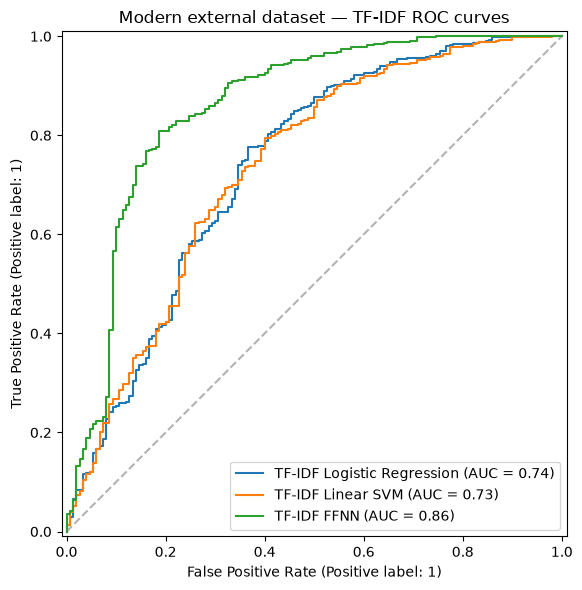

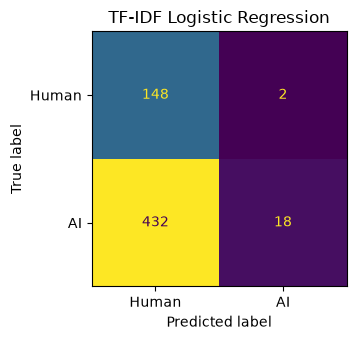

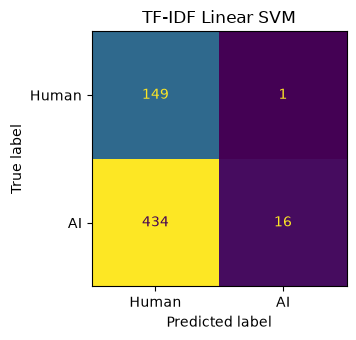

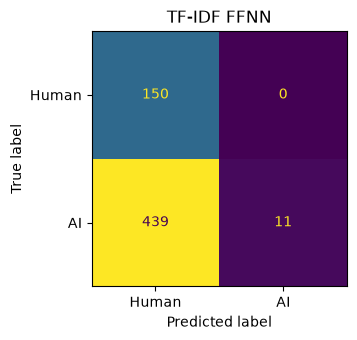

In [24]:
if not results:
    raise RuntimeError('No saved classifiers were found. Check models/tfidf.')
comparison = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(8, 6))
for name, scores in all_scores.items():
    RocCurveDisplay.from_predictions(modern['target'], scores, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', alpha=0.6)
ax.set_title('Modern external dataset — TF-IDF ROC curves')
plt.tight_layout()
plt.show()

for name, predictions in all_predictions.items():
    fig, ax = plt.subplots(figsize=(4.5, 3.5))
    ConfusionMatrixDisplay.from_predictions(
        modern['target'], predictions, labels=[0, 1],
        display_labels=['Human', 'AI'], ax=ax, colorbar=False,
    )
    ax.set_title(name)
    plt.tight_layout()
    plt.show()


## 7. Break down performance by generator

For human responses, the reported rate is the fraction incorrectly labeled AI. For each AI generator, it is recall (fraction correctly labeled AI).

In [25]:
rows = []
for name, scores in all_scores.items():
    predictions = all_predictions[name]
    for generator in ['human', 'chatgpt', 'claude', 'gemini']:
        mask = modern['model'].astype(str).str.lower().eq(generator).to_numpy()
        if not mask.any():
            continue
        rows.append({
            'model': name,
            'generator': generator,
            'n': int(mask.sum()),
            'metric': 'human_false_positive_rate' if generator == 'human' else 'ai_recall',
            'rate': float(predictions[mask].mean()),
        })
generator_comparison = pd.DataFrame(rows)
display(generator_comparison.round(4))


,model,generator,n,metric,rate
0,TF-IDF Logistic Regression,human,150,human_false_positive_rate,0.0133
1,TF-IDF Logistic Regression,chatgpt,150,ai_recall,0.0267
2,TF-IDF Logistic Regression,claude,150,ai_recall,0.0933
3,TF-IDF Logistic Regression,gemini,150,ai_recall,0.0000
4,TF-IDF Linear SVM,human,150,human_false_positive_rate,0.0067
5,TF-IDF Linear SVM,chatgpt,150,ai_recall,0.0133
6,TF-IDF Linear SVM,claude,150,ai_recall,0.0933
7,TF-IDF Linear SVM,gemini,150,ai_recall,0.0000
8,TF-IDF FFNN,human,150,human_false_positive_rate,0.0000
9,TF-IDF FFNN,chatgpt,150,ai_recall,0.0400


## 8. Export TF-IDF results for the comparison notebook

These exports can later be combined with the matching embedding evaluation exports. Avoid using modern labels to select a new training configuration or threshold.

In [26]:
comparison.to_csv(RESULTS_DIR / 'modern_tfidf_metrics.csv', index=False)
generator_comparison.to_csv(RESULTS_DIR / 'modern_tfidf_generator_metrics.csv', index=False)
prediction_export = modern[['id', 'model', 'label', 'target']].copy()
for name, scores in all_scores.items():
    prefix = name.lower().replace(' ', '_').replace('-', '_')
    prediction_export[f'{prefix}_score'] = scores
    prediction_export[f'{prefix}_prediction'] = all_predictions[name]
prediction_export.to_csv(RESULTS_DIR / 'modern_tfidf_predictions.csv', index=False)
print('Saved results in:', RESULTS_DIR)
print('Models evaluated:', len(results), 'of 3')


Saved results in: /Volumes/External SSD/Projects/coding-projects/BTT/Chewy-1B-spot-the-bot-detecting-ai-generated-text/data/evaluation
Models evaluated: 3 of 3
